# ACA 1 · Aprendizaje Automático
## ¿Quién se va, quién se queda y quién se gradúa? Predicción de la deserción estudiantil con Machine Learning clásico

**Corporación Unificada Nacional de Educación Superior (CUN)** · Escuela de Ingeniería · Especialización en Inteligencia Artificial
**Asignatura:** Aprendizaje Automático · **Docente:** Dr. Hamilton Rivera Flor

**Integrantes:**
- Bonny Darhyll Brayan Galindo Santos
- Andrés Alberto López Herrera
- Camilo José Rodríguez Ayubi

**Pilar:** 🎓 Proyecto 2 – Educación · **Dataset:** *Predict Students' Dropout and Academic Success* (UCI Machine Learning Repository, id 697)

Noviembre de 2026

### Contenido
0. Contexto, objetivo y pregunta orientadora
1. **Paso 1** – Exploración y EDA
2. **Paso 2** – Limpieza y preparación de datos
3. **Paso 3** – Modelado clásico (comparación, ajuste de hiperparámetros)
4. **Paso 4** – Evaluación y métricas
5. **Paso 5** – Exportación de artefactos para la app de Streamlit
6. Conclusiones y referencias (APA 7)

## 0. Contexto, objetivo y pregunta orientadora

En Colombia la deserción sigue siendo uno de los problemas más costosos de la educación superior. Con datos del SPADIES, el Laboratorio de Economía de la Educación de la Javeriana reportó para 2021-2 una deserción anual de 7,7 % en universidades y de 18,2 % en instituciones tecnológicas (LEE, 2023). Cada estudiante que se va representa matrícula perdida para la institución y, sobre todo, un proyecto de vida que se interrumpe.

La mayoría de las instituciones reacciona cuando el estudiante ya se fue. La idea de este trabajo es darle la vuelta: usar lo que la institución ya sabe de cada estudiante (datos de ingreso, situación económica y rendimiento del primer año) para estimar con anticipación su resultado final.

**Objetivo general.** Desarrollar una solución de Machine Learning clásico que, a partir de datos académicos, demográficos y socioeconómicos, clasifique a cada estudiante en *Deserción*, *Matriculado* o *Graduado*, desde la limpieza de datos hasta su despliegue en una aplicación interactiva de Streamlit.

**Pregunta orientadora.** ¿Cómo transformar datos de sectores estratégicos (en este caso, educación) en conocimiento predictivo mediante técnicas clásicas de Machine Learning y presentar los resultados en una interfaz interactiva accesible para usuarios finales?

**Sobre el dataset.** Lo publicaron Realinho et al. (2021) con registros de 4.424 estudiantes de pregrado del Instituto Politécnico de Portalegre (Portugal), matriculados entre 2008-09 y 2018-19 en 17 programas. Trae 36 variables y una variable objetivo con tres clases medidas al final de la duración normal del programa. Licencia CC BY 4.0.

In [1]:
# Librerías
import io, json, zipfile, urllib.request, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import sklearn

from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_validate,
                                     GridSearchCV, learning_curve)
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, label_binarize
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, precision_score,
                             recall_score, roc_auc_score, cohen_kappa_score, matthews_corrcoef,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve, auc)
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

SEED = 42
np.random.seed(SEED)
COLORES = {"Deserción": "#D1495B", "Matriculado": "#EDAE49", "Graduado": "#00798C"}
sns.set_theme(style="whitegrid", font_scale=0.95)
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 12})

FIGS = Path("figuras"); FIGS.mkdir(exist_ok=True)
Path("modelo").mkdir(exist_ok=True)
print("scikit-learn", sklearn.__version__, "| pandas", pd.__version__, "| numpy", np.__version__)

scikit-learn 1.9.1 | pandas 3.0.5 | numpy 2.5.3


### Módulo de preprocesamiento compartido

Las reglas de limpieza, los diccionarios de códigos y la ingeniería de características quedaron en un archivo aparte, `preprocesamiento.py`. La app de Streamlit importa exactamente el mismo archivo, de modo que un registro se procesa igual en el notebook y en la interfaz. La celda siguiente lo escribe en disco para que el notebook funcione solo, también en Google Colab.

In [2]:
%%writefile preprocesamiento.py
"""
preprocesamiento.py
-------------------
Módulo compartido entre el notebook y la app de Streamlit.
Contiene los diccionarios de códigos (traducidos al español), la limpieza del
dataset original de la UCI y el transformador de ingeniería de características
que va dentro del pipeline del modelo. Tenerlo en un solo archivo evita que el
notebook y la app terminen procesando los datos de forma distinta.

ACA 1 - Aprendizaje Automático | Especialización en IA - CUN
"""
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin

SEED = 42

# ---------------------------------------------------------------------------
# 1. Nombres de columnas: original UCI -> español (snake_case)
#    Ojo: en el CSV original la columna de jornada trae un tabulador al final
#    ("Daytime/evening attendance\t") y nacionalidad viene mal escrita
#    ("Nacionality"). Por eso se limpian los nombres antes de renombrar.
# ---------------------------------------------------------------------------
RENOMBRAR = {
    "Marital status": "estado_civil",
    "Application mode": "modo_ingreso",
    "Application order": "orden_opcion",
    "Course": "programa",
    "Daytime/evening attendance": "jornada_diurna",
    "Previous qualification": "formacion_previa",
    "Previous qualification (grade)": "nota_formacion_previa",
    "Nacionality": "nacionalidad",
    "Mother's qualification": "educacion_madre",
    "Father's qualification": "educacion_padre",
    "Mother's occupation": "ocupacion_madre",
    "Father's occupation": "ocupacion_padre",
    "Admission grade": "nota_admision",
    "Displaced": "desplazado",
    "Educational special needs": "necesidades_especiales",
    "Debtor": "deudor",
    "Tuition fees up to date": "matricula_al_dia",
    "Gender": "genero_masculino",
    "Scholarship holder": "becado",
    "Age at enrollment": "edad_ingreso",
    "International": "internacional",
    "Curricular units 1st sem (credited)": "s1_convalidadas",
    "Curricular units 1st sem (enrolled)": "s1_inscritas",
    "Curricular units 1st sem (evaluations)": "s1_evaluaciones",
    "Curricular units 1st sem (approved)": "s1_aprobadas",
    "Curricular units 1st sem (grade)": "s1_nota",
    "Curricular units 1st sem (without evaluations)": "s1_sin_evaluacion",
    "Curricular units 2nd sem (credited)": "s2_convalidadas",
    "Curricular units 2nd sem (enrolled)": "s2_inscritas",
    "Curricular units 2nd sem (evaluations)": "s2_evaluaciones",
    "Curricular units 2nd sem (approved)": "s2_aprobadas",
    "Curricular units 2nd sem (grade)": "s2_nota",
    "Curricular units 2nd sem (without evaluations)": "s2_sin_evaluacion",
    "Unemployment rate": "tasa_desempleo",
    "Inflation rate": "tasa_inflacion",
    "GDP": "pib",
    "Target": "resultado",
}

CLASES = {"Dropout": "Deserción", "Enrolled": "Matriculado", "Graduate": "Graduado"}
ORDEN_CLASES = ["Deserción", "Matriculado", "Graduado"]

# ---------------------------------------------------------------------------
# 2. Diccionarios de códigos (fuente: ficha del dataset en UCI, traducidos)
# ---------------------------------------------------------------------------
ESTADO_CIVIL = {1: "Soltero(a)", 2: "Casado(a)", 3: "Viudo(a)", 4: "Divorciado(a)",
                5: "Unión de hecho", 6: "Separado(a) legalmente"}

PROGRAMAS = {
    33: "Tecnologías de producción de biocombustibles",
    171: "Animación y diseño multimedia",
    8014: "Servicio social (nocturno)",
    9003: "Agronomía",
    9070: "Diseño de comunicación",
    9085: "Enfermería veterinaria",
    9119: "Ingeniería informática",
    9130: "Equinocultura",
    9147: "Administración",
    9238: "Servicio social",
    9254: "Turismo",
    9500: "Enfermería",
    9556: "Higiene oral",
    9670: "Publicidad y marketing",
    9773: "Periodismo y comunicación",
    9853: "Educación básica",
    9991: "Administración (nocturno)",
}

MODO_INGRESO = {
    1: "1.ª fase - contingente general",
    2: "Ordenanza 612/93",
    5: "1.ª fase - contingente especial (Azores)",
    7: "Titulado de otro programa superior",
    10: "Ordenanza 854-B/99",
    15: "Estudiante internacional (licenciatura)",
    16: "1.ª fase - contingente especial (Madeira)",
    17: "2.ª fase - contingente general",
    18: "3.ª fase - contingente general",
    26: "Ordenanza 533-A/99 b2 (plan diferente)",
    27: "Ordenanza 533-A/99 b3 (otra institución)",
    39: "Mayores de 23 años",
    42: "Traslado",
    43: "Cambio de programa",
    44: "Diploma de especialización tecnológica",
    51: "Cambio de institución/programa",
    53: "Diploma de ciclo corto",
    57: "Cambio de institución/programa (internacional)",
}

FORMACION_PREVIA = {
    1: "Secundaria completa", 2: "Superior - bachiller", 3: "Superior - licenciatura",
    4: "Superior - maestría", 5: "Superior - doctorado", 6: "Estudios superiores sin terminar",
    9: "12.º año sin terminar", 10: "11.º año sin terminar", 12: "Otro - 11.º año",
    14: "10.º año", 15: "10.º año sin terminar", 19: "Básica 3.er ciclo",
    38: "Básica 2.º ciclo", 39: "Especialización tecnológica", 40: "Superior - grado (1.er ciclo)",
    42: "Técnico superior profesional", 43: "Superior - maestría (2.º ciclo)",
}

# Agrupaciones para reducir categorías muy dispersas (29 a 46 códigos en los
# padres). Se agrupa por nivel educativo y por gran grupo ocupacional (CIUO).
NIVEL_EDUCATIVO = {
    "Sin estudios": [35, 36],
    "Básica": [11, 19, 26, 29, 30, 37, 38],
    "Media": [1, 9, 10, 12, 13, 14, 15, 18, 20, 25, 27, 31, 33],
    "Técnica/tecnológica": [22, 39, 42],
    "Superior": [2, 3, 4, 5, 6, 40, 41, 43, 44],
    "Desconocido": [34],
}
COD_A_NIVEL = {c: n for n, cods in NIVEL_EDUCATIVO.items() for c in cods}

GRUPO_OCUPACION = {
    0: "Estudiante", 1: "Directivos", 2: "Profesionales e intelectuales",
    3: "Técnicos de nivel medio", 4: "Personal administrativo", 5: "Servicios y ventas",
    6: "Agropecuario", 7: "Oficios industriales y construcción", 8: "Operadores de máquinas",
    9: "Trabajadores no calificados", 10: "Fuerzas armadas", 90: "Otra situación",
    99: "Sin información",
}


def grupo_ocupacion(codigo):
    """Lleva un código detallado (p. ej. 122, 153) a su gran grupo (2, 5)."""
    if pd.isna(codigo):
        return np.nan
    c = int(codigo)
    if c in GRUPO_OCUPACION:
        return GRUPO_OCUPACION[c]
    if 101 <= c <= 103:
        return GRUPO_OCUPACION[10]
    if 110 <= c <= 199:
        return GRUPO_OCUPACION.get(c // 10 - 10, "Otra situación")
    return "Otra situación"


# ---------------------------------------------------------------------------
# 3. Limpieza del dataset original
# ---------------------------------------------------------------------------
CURRICULARES = [f"s{s}_{v}" for s in (1, 2) for v in
                ("convalidadas", "inscritas", "evaluaciones", "aprobadas", "nota", "sin_evaluacion")]


def limpiar_dataset(df_original: pd.DataFrame) -> pd.DataFrame:
    """Normaliza nombres, traduce el objetivo y marca como faltantes los
    registros inconsistentes. Devuelve un DataFrame nuevo."""
    df = df_original.copy()
    df.columns = [c.strip().replace("\t", "") for c in df.columns]
    df = df.rename(columns=RENOMBRAR)

    # (a) Programa 171 (Animación y diseño multimedia): los 180 estudiantes que
    #     tiene registran 0 unidades inscritas, evaluadas y aprobadas en ambos
    #     semestres, incluso los que se graduaron. No son ceros reales sino
    #     ausencia de registro, así que se pasan a NaN para imputarlos.
    sin_registro = (df["s1_inscritas"] == 0) & (df["s2_inscritas"] == 0)
    df["sin_registro_curricular"] = sin_registro.astype(int)
    df.loc[sin_registro, CURRICULARES] = np.nan

    # (b) En Portugal se aprueba con 10/20. Un promedio de aprobadas por debajo
    #     de 10 con unidades aprobadas es imposible -> NaN.
    for s in (1, 2):
        malo = (df[f"s{s}_aprobadas"] > 0) & (df[f"s{s}_nota"] < 10)
        df.loc[malo, f"s{s}_nota"] = np.nan

    # (c) 'nacionalidad' es redundante con 'internacional' (coinciden en el
    #     100 % de los registros), se conserva solo la binaria.
    df = df.drop(columns=["nacionalidad"])

    if "resultado" in df.columns:
        df["resultado"] = df["resultado"].map(CLASES)
    return df


# ---------------------------------------------------------------------------
# 4. Ingeniería de características (va dentro del pipeline)
# ---------------------------------------------------------------------------
def _razon(num, den):
    num = pd.to_numeric(num, errors="coerce")
    den = pd.to_numeric(den, errors="coerce")
    return np.where(den > 0, num / den.where(den > 0, 1), np.where(den == 0, 0.0, np.nan))


class IngenieriaCaracteristicas(BaseEstimator, TransformerMixin):
    """Crea variables derivadas y agrupa códigos de alta cardinalidad.
    Solo calcula lo que las columnas disponibles permiten, así sirve para los
    tres escenarios (al ingreso, tras el 1.er semestre y tras el 1.er año)."""

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X.copy()
        for s in (1, 2):
            if {f"s{s}_aprobadas", f"s{s}_inscritas"} <= set(X.columns):
                X[f"s{s}_tasa_aprobacion"] = _razon(X[f"s{s}_aprobadas"], X[f"s{s}_inscritas"])
        if "s2_tasa_aprobacion" in X.columns:
            X["tasa_aprobacion_anual"] = _razon(X["s1_aprobadas"] + X["s2_aprobadas"],
                                                X["s1_inscritas"] + X["s2_inscritas"])
            X["cambio_nota"] = X["s2_nota"] - X["s1_nota"]
            X["cambio_tasa_aprobacion"] = X["s2_tasa_aprobacion"] - X["s1_tasa_aprobacion"]
        X["nivel_educ_madre"] = X["educacion_madre"].map(COD_A_NIVEL)
        X["nivel_educ_padre"] = X["educacion_padre"].map(COD_A_NIVEL)
        X["nivel_formacion_previa"] = X["formacion_previa"].map(COD_A_NIVEL)
        X["grupo_ocup_madre"] = X["ocupacion_madre"].map(grupo_ocupacion)
        X["grupo_ocup_padre"] = X["ocupacion_padre"].map(grupo_ocupacion)
        return X


# ---------------------------------------------------------------------------
# 5. Columnas por escenario
#    - "ingreso":   solo lo que se sabe el día de la matrícula
#    - "semestre1": + resultados del primer semestre
#    - "anual":     + resultados del segundo semestre (modelo principal)
# ---------------------------------------------------------------------------
ESCENARIOS = {
    "ingreso": "Al ingreso (sin notas)",
    "semestre1": "Tras el 1.er semestre",
    "anual": "Tras el 1.er año (modelo principal)",
}

_BASE_NUM = ["orden_opcion", "nota_formacion_previa", "nota_admision", "edad_ingreso",
             "tasa_desempleo", "tasa_inflacion", "pib"]
_S1_NUM = ["s1_convalidadas", "s1_inscritas", "s1_evaluaciones", "s1_aprobadas", "s1_nota",
           "s1_sin_evaluacion", "s1_tasa_aprobacion"]
_S2_NUM = ["s2_convalidadas", "s2_inscritas", "s2_evaluaciones", "s2_aprobadas", "s2_nota",
           "s2_sin_evaluacion", "s2_tasa_aprobacion", "tasa_aprobacion_anual", "cambio_nota",
           "cambio_tasa_aprobacion"]
_BASE_BIN = ["jornada_diurna", "desplazado", "necesidades_especiales", "deudor", "matricula_al_dia",
             "genero_masculino", "becado", "internacional"]
CATEGORICAS = ["estado_civil", "modo_ingreso", "programa", "nivel_formacion_previa",
               "nivel_educ_madre", "nivel_educ_padre", "grupo_ocup_madre", "grupo_ocup_padre"]
_BASE_ENT = ["estado_civil", "modo_ingreso", "orden_opcion", "programa", "jornada_diurna",
             "formacion_previa", "nota_formacion_previa", "educacion_madre", "educacion_padre",
             "ocupacion_madre", "ocupacion_padre", "nota_admision", "desplazado",
             "necesidades_especiales", "deudor", "matricula_al_dia", "genero_masculino", "becado",
             "edad_ingreso", "internacional", "tasa_desempleo", "tasa_inflacion", "pib"]
_S1_ENT = [c for c in CURRICULARES if c.startswith("s1_")]
_S2_ENT = [c for c in CURRICULARES if c.startswith("s2_")]


def columnas(escenario: str = "anual") -> dict:
    """Devuelve las listas de columnas (entrada, numéricas, binarias y
    categóricas) que usa cada escenario."""
    if escenario == "ingreso":
        return {"entradas": _BASE_ENT, "numericas": _BASE_NUM,
                "binarias": _BASE_BIN, "categoricas": CATEGORICAS}
    if escenario == "semestre1":
        return {"entradas": _BASE_ENT + _S1_ENT + ["sin_registro_curricular"],
                "numericas": _BASE_NUM + _S1_NUM,
                "binarias": _BASE_BIN + ["sin_registro_curricular"], "categoricas": CATEGORICAS}
    if escenario == "anual":
        return {"entradas": _BASE_ENT + _S1_ENT + _S2_ENT + ["sin_registro_curricular"],
                "numericas": _BASE_NUM + _S1_NUM + _S2_NUM,
                "binarias": _BASE_BIN + ["sin_registro_curricular"], "categoricas": CATEGORICAS}
    raise ValueError(f"Escenario desconocido: {escenario}")


# Nombres legibles para gráficas y para la app
ETIQUETAS = {
    "estado_civil": "Estado civil", "modo_ingreso": "Modalidad de ingreso",
    "orden_opcion": "Orden de preferencia del programa", "programa": "Programa",
    "jornada_diurna": "Jornada diurna", "formacion_previa": "Formación previa",
    "nota_formacion_previa": "Nota de formación previa", "educacion_madre": "Educación de la madre",
    "educacion_padre": "Educación del padre", "ocupacion_madre": "Ocupación de la madre",
    "ocupacion_padre": "Ocupación del padre", "nota_admision": "Nota de admisión",
    "desplazado": "Vive fuera de su ciudad", "necesidades_especiales": "Necesidades educativas especiales",
    "deudor": "Deudor", "matricula_al_dia": "Matrícula al día", "genero_masculino": "Género (hombre)",
    "becado": "Becado", "edad_ingreso": "Edad de ingreso", "internacional": "Estudiante internacional",
    "s1_convalidadas": "S1 · unidades convalidadas", "s1_inscritas": "S1 · unidades inscritas",
    "s1_evaluaciones": "S1 · evaluaciones presentadas", "s1_aprobadas": "S1 · unidades aprobadas",
    "s1_nota": "S1 · promedio de notas", "s1_sin_evaluacion": "S1 · unidades sin evaluación",
    "s2_convalidadas": "S2 · unidades convalidadas", "s2_inscritas": "S2 · unidades inscritas",
    "s2_evaluaciones": "S2 · evaluaciones presentadas", "s2_aprobadas": "S2 · unidades aprobadas",
    "s2_nota": "S2 · promedio de notas", "s2_sin_evaluacion": "S2 · unidades sin evaluación",
    "tasa_desempleo": "Tasa de desempleo (%)", "tasa_inflacion": "Tasa de inflación (%)", "pib": "PIB (variación %)",
    "sin_registro_curricular": "Sin registro curricular",
}
ETIQUETAS.update({
    "s1_tasa_aprobacion": "S1 · tasa de aprobación", "s2_tasa_aprobacion": "S2 · tasa de aprobación",
    "tasa_aprobacion_anual": "Tasa de aprobación del año", "cambio_nota": "Cambio de promedio S1 → S2",
    "cambio_tasa_aprobacion": "Cambio de tasa de aprobación S1 → S2",
    "nivel_formacion_previa": "Nivel de formación previa", "nivel_educ_madre": "Nivel educativo de la madre",
    "nivel_educ_padre": "Nivel educativo del padre", "grupo_ocup_madre": "Ocupación de la madre",
    "grupo_ocup_padre": "Ocupación del padre",
})

# Código representativo de cada nivel/grupo: el modelo solo usa el nivel
# agrupado, así que en la app basta con elegir el nivel.
CODIGO_NIVEL = {"Sin estudios": 35, "Básica": 19, "Media": 1, "Técnica/tecnológica": 39,
                "Superior": 3, "Desconocido": 34}
CODIGO_OCUPACION = {v: k for k, v in GRUPO_OCUPACION.items()}

Overwriting preprocesamiento.py


In [3]:
import importlib, preprocesamiento as pp
importlib.reload(pp)

<module 'preprocesamiento' from '/home/claude/aca/app/preprocesamiento.py'>

---
## Paso 1 · Exploración y EDA

### 1.1 Carga de datos
Se descarga el archivo oficial desde el repositorio de la UCI. Si ya existe una copia local en `data/data.csv` se usa esa, para no depender de la conexión.

In [4]:
URL_UCI = "https://archive.ics.uci.edu/static/public/697/predict+students+dropout+and+academic+success.zip"
RUTA = Path("data/data.csv")

def cargar_datos():
    if not RUTA.exists():
        RUTA.parent.mkdir(exist_ok=True)
        with urllib.request.urlopen(URL_UCI, timeout=60) as r:
            z = zipfile.ZipFile(io.BytesIO(r.read()))
        nombre = [n for n in z.namelist() if n.endswith(".csv")][0]
        RUTA.write_bytes(z.read(nombre))
    # El archivo usa ';' como separador y trae BOM al inicio
    return pd.read_csv(RUTA, sep=";", encoding="utf-8-sig")

crudo = cargar_datos()
print(f"Registros: {crudo.shape[0]:,} | Columnas: {crudo.shape[1]}")
crudo.head()

Registros: 4,424 | Columnas: 37


,Marital status,Application mode,Application order,Course,Daytime/evening attendance\t,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,Mother's occupation,Father's occupation,Admission grade,Displaced,Educational special needs,Debtor,Tuition fees up to date,Gender,Scholarship holder,Age at enrollment,International,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.000,1,19,12,5,9,127.300,1,0,0,1,1,0,20,0,0,0,0,0,0.000,0,0,0,0,0,0.000,0,10.800,1.400,1.740,Dropout
1,1,15,1,9254,1,1,160.000,1,1,3,3,3,142.500,1,0,0,0,1,0,19,0,0,6,6,6,14.000,0,0,6,6,6,13.667,0,13.900,-0.300,0.790,Graduate
2,1,1,5,9070,1,1,122.000,1,37,37,9,9,124.800,1,0,0,0,1,0,19,0,0,6,0,0,0.000,0,0,6,0,0,0.000,0,10.800,1.400,1.740,Dropout
3,1,17,2,9773,1,1,122.000,1,38,37,5,3,119.600,1,0,0,1,0,0,20,0,0,6,8,6,13.429,0,0,6,10,5,12.400,0,9.400,-0.800,-3.120,Graduate
4,2,39,1,8014,0,1,100.000,1,37,38,9,9,141.500,0,0,0,1,0,0,45,0,0,6,9,5,12.333,0,0,6,6,6,13.000,0,13.900,-0.300,0.790,Graduate


### 1.2 Estructura, tipos y calidad básica

In [5]:
resumen = pd.DataFrame({
    "tipo": crudo.dtypes.astype(str),
    "nulos": crudo.isna().sum(),
    "valores_unicos": crudo.nunique(),
    "min": crudo.min(numeric_only=True),
    "max": crudo.max(numeric_only=True),
})
print("Valores nulos totales:", int(crudo.isna().sum().sum()))
print("Filas duplicadas:", int(crudo.duplicated().sum()))
print("Columnas con espacios o tabuladores en el nombre:",
      [c for c in crudo.columns if c != c.strip()])
resumen

Valores nulos totales: 0
Filas duplicadas: 0
Columnas con espacios o tabuladores en el nombre: ['Daytime/evening attendance\t']


,tipo,nulos,valores_unicos,min,max
Admission grade,float64,0,620,95.000,190.000
Age at enrollment,int64,0,46,17.000,70.000
Application mode,int64,0,18,1.000,57.000
Application order,int64,0,8,0.000,9.000
Course,int64,0,17,33.000,"9,991.000"
Curricular units 1st sem (approved),int64,0,23,0.000,26.000
Curricular units 1st sem (credited),int64,0,21,0.000,20.000
Curricular units 1st sem (enrolled),int64,0,23,0.000,26.000
Curricular units 1st sem (evaluations),int64,0,35,0.000,45.000
Curricular units 1st sem (grade),float64,0,805,0.000,18.875


A primera vista el dataset está "limpio": sin nulos y sin duplicados. Pero hay detalles que no se ven en un `info()`: una columna trae un tabulador pegado al nombre (`'Daytime/evening attendance\t'`), *Nationality* viene mal escrita (`Nacionality`) y casi todas las variables categóricas están guardadas como números enteros (códigos), así que no deben tratarse como cantidades. Para trabajar con más claridad se renombran las columnas al español con el módulo compartido y luego se revisa la coherencia interna de los datos.

In [6]:
df_eda = crudo.copy()
df_eda.columns = [c.strip() for c in df_eda.columns]
df_eda = df_eda.rename(columns=pp.RENOMBRAR)
df_eda["resultado"] = df_eda["resultado"].map(pp.CLASES)
df_eda["programa_nombre"] = df_eda["programa"].map(pp.PROGRAMAS)
df_eda.sample(3, random_state=SEED).T.head(15)

,1255,3458,3390
estado_civil,4,1,1
modo_ingreso,39,17,17
orden_opcion,1,1,1
programa,9130,9238,9853
jornada_diurna,1,1,1
formacion_previa,1,1,1
nota_formacion_previa,133.100,125.000,133.000
nacionalidad,1,1,1
educacion_madre,3,4,38
educacion_padre,1,3,38


### 1.3 Variable objetivo

,estudiantes,porcentaje
resultado,,
Deserción,1421,32.100
Matriculado,794,17.900
Graduado,2209,49.900


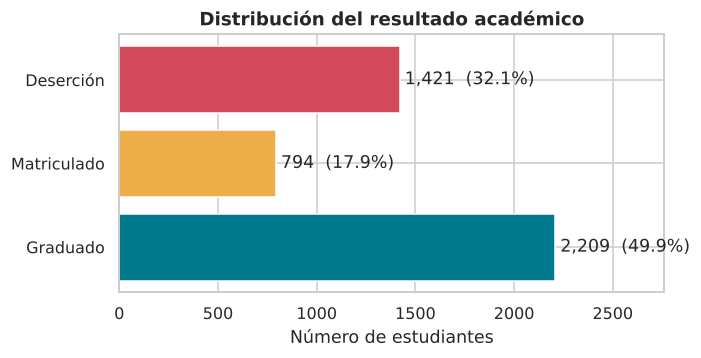

In [7]:
conteo = df_eda["resultado"].value_counts().reindex(pp.ORDEN_CLASES)
prop = conteo / conteo.sum()
display(pd.DataFrame({"estudiantes": conteo, "porcentaje": (prop * 100).round(1)}))

fig, ax = plt.subplots(figsize=(6.5, 3.4))
bars = ax.barh(conteo.index, conteo.values, color=[COLORES[c] for c in conteo.index])
for b, n, p in zip(bars, conteo.values, prop.values):
    ax.text(b.get_width() + 25, b.get_y() + b.get_height() / 2, f"{n:,}  ({p:.1%})", va="center")
ax.invert_yaxis(); ax.set_xlim(0, conteo.max() * 1.25)
ax.set_title("Distribución del resultado académico"); ax.set_xlabel("Número de estudiantes")
plt.tight_layout(); plt.savefig(FIGS / "01_objetivo.png", dpi=200, bbox_inches="tight"); plt.show()

Uno de cada dos estudiantes se gradúa (49,9 %), casi uno de cada tres deserta (32,1 %) y el 17,9 % sigue matriculado cuando se cumple el tiempo normal del programa. El desbalance no es extremo, pero *Matriculado* tiene menos de la mitad de casos que *Graduado*. Eso obliga a estratificar las particiones y a escoger métricas que no premien ignorar a la clase pequeña.

### 1.4 Rendimiento académico frente al resultado

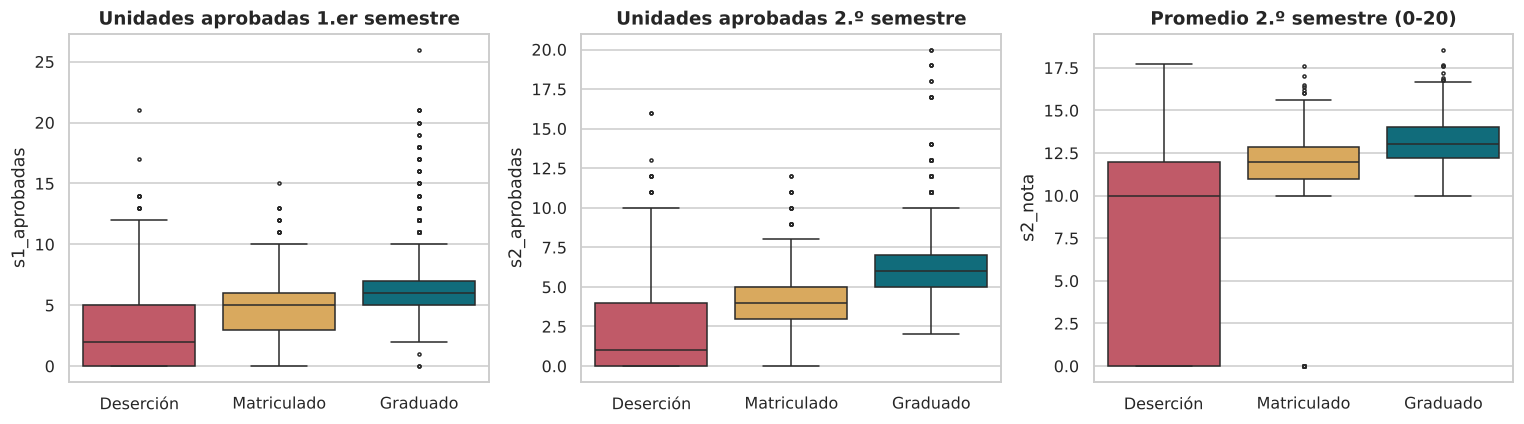

,nota_admision,s1_aprobadas,s1_nota,s2_aprobadas,s2_nota
resultado,,,,,
Deserción,123.000,2.000,11.000,1.000,10.000
Matriculado,123.900,5.000,12.000,4.000,12.000
Graduado,127.100,6.000,13.018,6.000,13.000


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
vars_ = [("s1_aprobadas", "Unidades aprobadas 1.er semestre"),
         ("s2_aprobadas", "Unidades aprobadas 2.º semestre"),
         ("s2_nota", "Promedio 2.º semestre (0-20)")]
for ax, (v, t) in zip(axes, vars_):
    sns.boxplot(data=df_eda[df_eda["s1_inscritas"] > 0], x="resultado", y=v, order=pp.ORDEN_CLASES,
                palette=COLORES, ax=ax, fliersize=2)
    ax.set_title(t); ax.set_xlabel("")
plt.tight_layout(); plt.savefig(FIGS / "02_academico.png", dpi=200, bbox_inches="tight"); plt.show()

df_eda[df_eda["s1_inscritas"] > 0].groupby("resultado")[
    ["nota_admision", "s1_aprobadas", "s1_nota", "s2_aprobadas", "s2_nota"]].median().reindex(pp.ORDEN_CLASES)

La separación es clara. Quien deserta aprueba en el segundo semestre una mediana de 1 unidad; quien sigue matriculado, 4, y quien se gradúa, 6. La nota de admisión, en cambio, casi no distingue a los grupos (123 frente a 127 de mediana). Lo que ocurre durante el primer año dice mucho más que el puntaje con el que se entró.

*En estas gráficas se excluyen los 180 estudiantes sin registro curricular, un problema que se trata en el Paso 2.*

### 1.5 Factores económicos y demográficos

tasa_desercion_%     n
matricula_al_dia Matrícula NO al día            86.600   528
                 Matrícula al día               24.700  3896
deudor           No deudor                      28.300  3921
                 Deudor                         62.000   503
becado           Sin beca                       38.700  3325
                 Becado                         12.200  1099
genero_masculino Mujer                          25.100  2868
                 Hombre                         45.100  1556
jornada_diurna   Nocturna                       42.900   483
                 Diurna                         30.800  3941

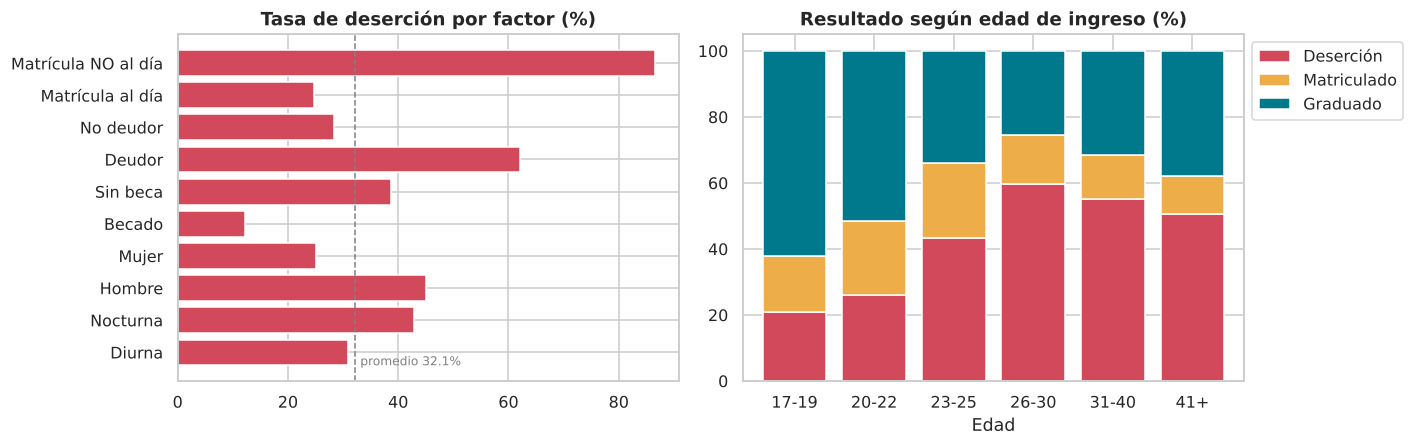

In [9]:
def tasa_desercion(col, etiquetas=None):
    t = pd.crosstab(df_eda[col], df_eda["resultado"], normalize="index")["Deserción"] * 100
    n = df_eda[col].value_counts()
    out = pd.DataFrame({"tasa_desercion_%": t.round(1), "n": n})
    if etiquetas: out.index = out.index.map(etiquetas)
    return out

factores = {
    "matricula_al_dia": {0: "Matrícula NO al día", 1: "Matrícula al día"},
    "deudor": {0: "No deudor", 1: "Deudor"},
    "becado": {0: "Sin beca", 1: "Becado"},
    "genero_masculino": {0: "Mujer", 1: "Hombre"},
    "jornada_diurna": {0: "Nocturna", 1: "Diurna"},
}
tabla_f = pd.concat({k: tasa_desercion(k, v) for k, v in factores.items()})
display(tabla_f)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
tf = tabla_f.reset_index(level=1)
axes[0].barh(tf["level_1"], tf["tasa_desercion_%"], color="#D1495B")
axes[0].axvline(prop["Deserción"] * 100, ls="--", c="gray", lw=1)
axes[0].text(prop["Deserción"] * 100 + 1, len(tf) - 0.6, f"promedio {prop['Deserción']:.1%}", color="gray", fontsize=8)
axes[0].set_title("Tasa de deserción por factor (%)"); axes[0].invert_yaxis()

edad = pd.cut(df_eda["edad_ingreso"], [16, 19, 22, 25, 30, 40, 71],
              labels=["17-19", "20-22", "23-25", "26-30", "31-40", "41+"])
pd.crosstab(edad, df_eda["resultado"], normalize="index")[pp.ORDEN_CLASES].mul(100).plot(
    kind="bar", stacked=True, color=COLORES.values(), ax=axes[1], width=0.8)
axes[1].set_title("Resultado según edad de ingreso (%)"); axes[1].set_xlabel("Edad")
axes[1].legend(title="", bbox_to_anchor=(1, 1)); axes[1].tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.savefig(FIGS / "03_factores.png", dpi=200, bbox_inches="tight"); plt.show()

El factor económico es el que más llama la atención: el 86,6 % de quienes no tienen la matrícula al día termina desertando, frente al 24,7 % de quienes pagan a tiempo. Ser deudor sube la deserción al 62,0 % y tener beca la baja al 12,2 %.

También desertan más los hombres (45,1 % contra 25,1 % de las mujeres), quienes estudian de noche (42,9 %) y quienes ingresan mayores: entre los 17 y 19 años deserta el 21,0 %, y entre los 26 y 30, el 59,8 %. Son asociaciones, no causas. La edad, por ejemplo, suele venir con trabajo y obligaciones familiares que el dataset no registra.

### 1.6 Deserción por programa

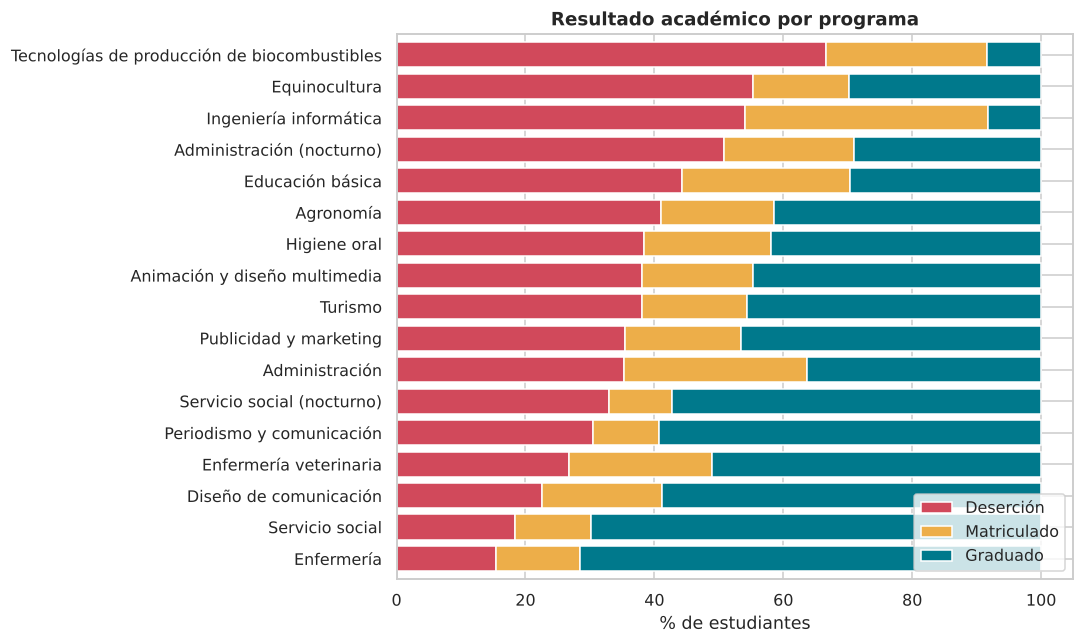

In [10]:
prog = pd.crosstab(df_eda["programa_nombre"], df_eda["resultado"], normalize="index")[pp.ORDEN_CLASES] * 100
prog = prog.sort_values("Deserción")
fig, ax = plt.subplots(figsize=(10, 6))
prog.plot(kind="barh", stacked=True, color=COLORES.values(), ax=ax, width=0.8)
ax.set_xlabel("% de estudiantes"); ax.set_ylabel(""); ax.set_title("Resultado académico por programa")
ax.legend(title="", loc="lower right")
plt.tight_layout(); plt.savefig(FIGS / "04_programas.png", dpi=200, bbox_inches="tight"); plt.show()

La diferencia entre programas es enorme. Enfermería, el programa más grande (766 estudiantes), tiene la deserción más baja (15,4 %), mientras que en Ingeniería informática deserta el 54,1 % y solo se gradúa el 8,2 % a tiempo. Biocombustibles muestra la tasa más alta (66,7 %), pero con apenas 12 estudiantes esa cifra es poco confiable. El programa entra al modelo como variable categórica.

### 1.7 Correlaciones de las variables numéricas

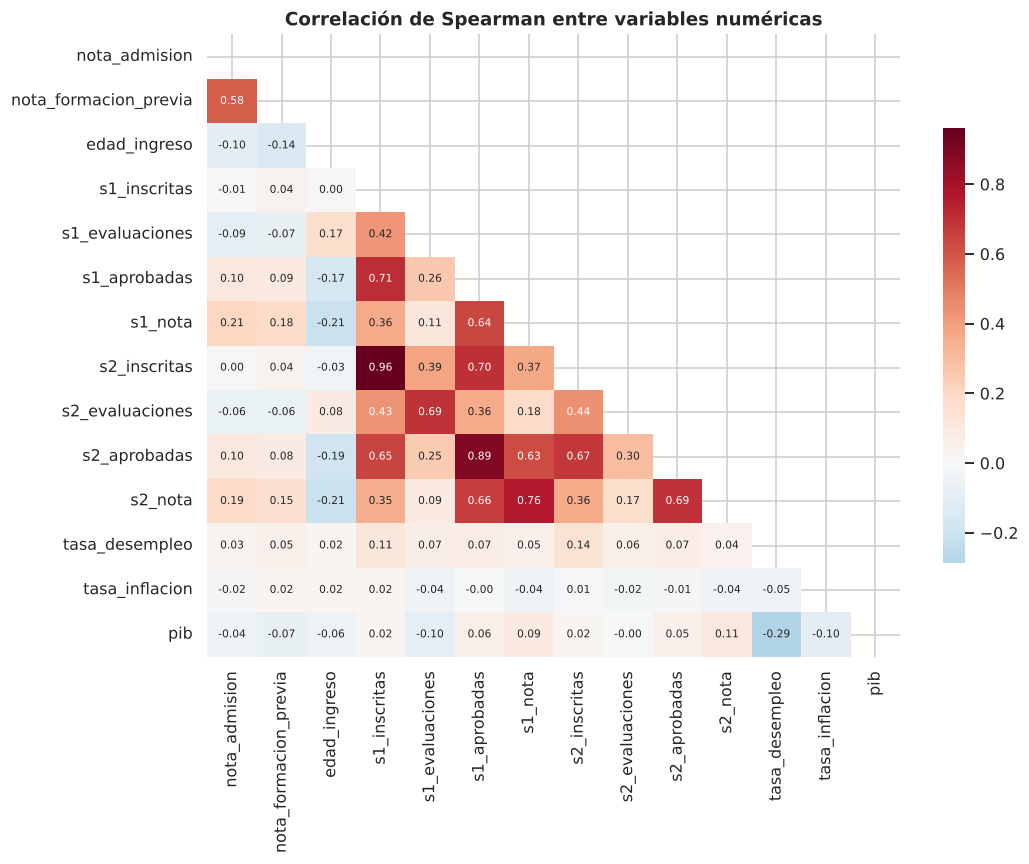

Valores distintos de las variables macroeconómicas: {'tasa_desempleo': 10, 'tasa_inflacion': 9, 'pib': 10}


In [11]:
num_cols = ["nota_admision", "nota_formacion_previa", "edad_ingreso", "s1_inscritas", "s1_evaluaciones",
            "s1_aprobadas", "s1_nota", "s2_inscritas", "s2_evaluaciones", "s2_aprobadas", "s2_nota",
            "tasa_desempleo", "tasa_inflacion", "pib"]
corr = df_eda[num_cols].corr(method="spearman")
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, mask=np.triu(np.ones_like(corr, dtype=bool)), cmap="RdBu_r", center=0,
            annot=True, fmt=".2f", annot_kws={"size": 7}, cbar_kws={"shrink": .7}, ax=ax)
ax.set_title("Correlación de Spearman entre variables numéricas")
plt.tight_layout(); plt.savefig(FIGS / "05_correlaciones.png", dpi=200, bbox_inches="tight"); plt.show()
print("Valores distintos de las variables macroeconómicas:",
      df_eda[["tasa_desempleo", "tasa_inflacion", "pib"]].nunique().to_dict())

Las variables de un mismo semestre se mueven juntas y el primer semestre anticipa al segundo: la correlación entre unidades aprobadas en S1 y S2 es de 0,88. Esa redundancia no afecta a los árboles, pero en la regresión logística se controla con la regularización (parámetro *C*). La nota de admisión casi no se relaciona con el rendimiento universitario (0,15 con aprobadas en S1).

Las tres variables macroeconómicas tienen solo 9 o 10 valores distintos: describen el año de ingreso de la cohorte, no al estudiante.

---
## Paso 2 · Limpieza y preparación de los datos

### 2.1 Pruebas de coherencia
Que no haya nulos no significa que los datos sean coherentes. Se verifican reglas de negocio que cualquier registro académico debería cumplir.

In [12]:
reglas = {}
for s in (1, 2):
    e, a, ev, n, c = (df_eda[f"s{s}_{v}"] for v in ("inscritas", "aprobadas", "evaluaciones", "nota", "convalidadas"))
    reglas[f"S{s}: aprobadas > inscritas"] = int((a > e).sum())
    reglas[f"S{s}: aprobadas > evaluaciones"] = int((a > ev).sum())
    reglas[f"S{s}: convalidadas > inscritas"] = int((c > e).sum())
    reglas[f"S{s}: nota > 0 sin aprobadas"] = int(((n > 0) & (a == 0)).sum())
    reglas[f"S{s}: aprobó pero promedio < 10 (se aprueba con 10/20)"] = int(((a > 0) & (n < 10)).sum())
    reglas[f"S{s}: 0 unidades inscritas"] = int((e == 0).sum())
reglas["Nacionalidad extranjera ≠ indicador 'internacional'"] = int(
    ((crudo["Nacionality"] != 1).astype(int) != crudo["International"]).sum())
reglas["Orden de opción fuera de 1-6 (0 o 9)"] = int((~df_eda["orden_opcion"].between(1, 6)).sum())
pd.Series(reglas, name="registros").to_frame()

,registros
S1: aprobadas > inscritas,0
S1: aprobadas > evaluaciones,0
S1: convalidadas > inscritas,0
S1: nota > 0 sin aprobadas,0
S1: aprobó pero promedio < 10 (se aprueba con 10/20),1
S1: 0 unidades inscritas,180
S2: aprobadas > inscritas,0
S2: aprobadas > evaluaciones,0
S2: convalidadas > inscritas,0
S2: nota > 0 sin aprobadas,0


In [13]:
sin_insc = df_eda[(df_eda["s1_inscritas"] == 0) & (df_eda["s2_inscritas"] == 0)]
print("Estudiantes con 0 unidades inscritas en ambos semestres:", len(sin_insc))
print("Programas a los que pertenecen:", sin_insc["programa_nombre"].value_counts().to_dict())
print("Total de estudiantes de ese programa:", (df_eda["programa"] == 171).sum())
print("Unidades convalidadas promedio:", sin_insc[["s1_convalidadas", "s2_convalidadas"]].mean().round(2).to_dict())
sin_insc["resultado"].value_counts().reindex(pp.ORDEN_CLASES).to_frame("estudiantes")

Estudiantes con 0 unidades inscritas en ambos semestres: 180
Programas a los que pertenecen: {'Animación y diseño multimedia': 180}
Total de estudiantes de ese programa: 215
Unidades convalidadas promedio: {'s1_convalidadas': 0.0, 's2_convalidadas': 0.0}


,estudiantes
resultado,
Deserción,77
Matriculado,28
Graduado,75


**Hallazgo clave de calidad.** Los 180 estudiantes con cero unidades inscritas en los dos semestres pertenecen todos a *Animación y diseño multimedia* (código 171; son 180 de sus 215 estudiantes) y 75 de ellos aparecen como **graduados**. Graduarse sin haber inscrito una sola unidad es imposible, así que esos ceros no describen al estudiante: son un vacío de registro de ese programa. Si se dejaran como ceros, el modelo aprendería que "no inscribir nada" se asocia con graduarse, lo cual es falso.

Decisiones de limpieza (todas implementadas en `pp.limpiar_dataset`):

| Problema | Registros | Tratamiento |
|---|---|---|
| Ceros estructurales del programa 171 en las 12 variables curriculares | 180 | Se convierten a `NaN`, se imputan con la mediana dentro del pipeline y se agrega el indicador `sin_registro_curricular` |
| Promedio < 10 con unidades aprobadas | 1 | Se marca `NaN` y se imputa |
| `Nacionality` duplica a `International` | 4.424 | Se elimina `nacionalidad` (redundante) |
| Tabulador y error ortográfico en nombres | 2 columnas | Se normalizan nombres y se traducen |
| Orden de opción 0 y 9 | 2 | Se conservan: la ficha de la UCI documenta el rango 0-9 |
| Edades de hasta 70 años, notas de 95 a 190 | — | Se conservan: son valores plausibles, no errores. El escalado estándar y los modelos usados toleran estos rangos |

In [14]:
df = pp.limpiar_dataset(crudo)
print("Forma tras la limpieza:", df.shape)
print("Nulos introducidos a propósito (para imputar):")
df.isna().sum()[lambda s: s > 0].to_frame("nulos")

Forma tras la limpieza: (4424, 37)
Nulos introducidos a propósito (para imputar):


,nulos
s1_convalidadas,180
s1_inscritas,180
s1_evaluaciones,180
s1_aprobadas,180
s1_nota,181
s1_sin_evaluacion,180
s2_convalidadas,180
s2_inscritas,180
s2_evaluaciones,180
s2_aprobadas,180


### 2.2 Valores atípicos
Se revisan con el criterio de Tukey (1,5 × RIC). El objetivo no es borrar todo lo que se salga de la caja, sino decidir si cada caso es un error o una realidad del fenómeno.

In [15]:
def atipicos_iqr(s):
    q1, q3 = s.quantile([.25, .75]); r = q3 - q1
    return int(((s < q1 - 1.5 * r) | (s > q3 + 1.5 * r)).sum())

cols_out = ["edad_ingreso", "nota_admision", "nota_formacion_previa", "s1_nota", "s2_nota",
            "s1_inscritas", "s2_inscritas", "s1_evaluaciones", "s2_evaluaciones"]
out = pd.DataFrame({"atipicos_iqr": {c: atipicos_iqr(df[c].dropna()) for c in cols_out},
                    "min": df[cols_out].min(), "mediana": df[cols_out].median(), "max": df[cols_out].max()})
out["%"] = (out["atipicos_iqr"] / len(df) * 100).round(1)
out

,atipicos_iqr,min,mediana,max,%
edad_ingreso,441,17.000,20.000,70.000,10.000
nota_admision,86,95.000,126.100,190.000,1.900
nota_formacion_previa,179,95.000,133.100,190.000,4.000
s1_nota,556,0.000,12.333,18.875,12.600
s2_nota,698,0.000,12.333,18.571,15.800
s1_inscritas,372,1.000,6.000,26.000,8.400
s2_inscritas,189,1.000,6.000,23.000,4.300
s1_evaluaciones,458,0.000,8.000,45.000,10.400
s2_evaluaciones,109,0.000,8.000,33.000,2.500


Ningún registro se elimina. Los "atípicos" de edad son los mayores de 34 años (10 % del total), una población real que en buena parte entró por la modalidad *Mayores de 23 años*. Los de las notas de semestre son, sobre todo, ceros: estudiantes que no aprobaron nada (690 en el segundo semestre). Ese cero no es un error, es la señal más fuerte del dataset: el 94,2 % de esos estudiantes desertó. Borrarlos sería borrar justo los casos que se quieren detectar. El escalado estándar y la regularización bastan para manejar estos rangos.

### 2.3 Ingeniería de características
A partir de la exploración se crean variables que resumen mejor el desempeño del primer año. Todas viven en la clase `IngenieriaCaracteristicas` del módulo compartido, dentro del pipeline, así que se recalculan solas cuando la app recibe un estudiante nuevo:

- **Tasas de aprobación** por semestre y anual (aprobadas ÷ inscritas): normalizan la carga de cada estudiante.
- **Cambio de nota y de tasa de aprobación** entre semestres: captura si el estudiante mejora o empeora.
- **Nivel educativo de madre, padre y del propio estudiante**: los 29-34 códigos originales se agrupan en 6 niveles.
- **Gran grupo ocupacional de madre y padre**: los 32-46 códigos detallados se llevan a los grandes grupos de la clasificación de ocupaciones.

In [16]:
fe = pp.IngenieriaCaracteristicas().fit_transform(df)
nuevas = ["s1_tasa_aprobacion", "s2_tasa_aprobacion", "tasa_aprobacion_anual", "cambio_nota",
          "cambio_tasa_aprobacion"]
display(fe.groupby("resultado")[nuevas].median().reindex(pp.ORDEN_CLASES))
print("Cardinalidad antes → después de agrupar:")
for a, b in [("educacion_madre", "nivel_educ_madre"), ("educacion_padre", "nivel_educ_padre"),
             ("ocupacion_madre", "grupo_ocup_madre"), ("ocupacion_padre", "grupo_ocup_padre"),
             ("formacion_previa", "nivel_formacion_previa")]:
    print(f"  {a:<18} {fe[a].nunique():>3}  →  {b:<24} {fe[b].nunique():>2}")

,s1_tasa_aprobacion,s2_tasa_aprobacion,tasa_aprobacion_anual,cambio_nota,cambio_tasa_aprobacion
resultado,,,,,
Deserción,0.400,0.167,0.300,0.000,0.000
Matriculado,0.800,0.714,0.750,0.000,0.000
Graduado,1.000,1.000,1.000,0.000,0.000


Cardinalidad antes → después de agrupar:
  educacion_madre     29  →  nivel_educ_madre          6
  educacion_padre     34  →  nivel_educ_padre          6
  ocupacion_madre     32  →  grupo_ocup_madre         13
  ocupacion_padre     46  →  grupo_ocup_padre         13
  formacion_previa    17  →  nivel_formacion_previa    4


### 2.4 Partición de datos y pipeline de preprocesamiento
Se separa un 20 % de prueba **estratificado** (misma proporción de clases) que no se toca hasta la evaluación final; así lo recomiendan también los autores del dataset. Todo el preprocesamiento va dentro de un `Pipeline`, de modo que la imputación y el escalado se ajustan solo con los datos de entrenamiento de cada pliegue y no hay fuga de información.

| Tipo | Tratamiento |
|---|---|
| Numéricas (24) | Imputación por mediana + `StandardScaler` |
| Binarias (9) | Imputación por moda, se dejan en 0/1 |
| Categóricas (8) | Imputación por moda + `OneHotEncoder`; las categorías con menos de 20 casos se agrupan como "infrecuentes" |

In [17]:
COLS = pp.columnas("anual")
X = df[COLS["entradas"]]
y = df["resultado"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
print(f"Entrenamiento: {X_train.shape} | Prueba: {X_test.shape}")
pd.DataFrame({"train %": y_train.value_counts(normalize=True) * 100,
              "test %": y_test.value_counts(normalize=True) * 100}).reindex(pp.ORDEN_CLASES).round(1)

Entrenamiento: (3539, 36) | Prueba: (885, 36)


,train %,test %
resultado,,
Deserción,32.100,32.100
Matriculado,17.900,18.000
Graduado,49.900,49.900


In [18]:
def crear_preprocesador(cols):
    return ColumnTransformer([
        ("num", Pipeline([("imputar", SimpleImputer(strategy="median")),
                          ("escalar", StandardScaler())]), cols["numericas"]),
        ("bin", SimpleImputer(strategy="most_frequent"), cols["binarias"]),
        ("cat", Pipeline([("imputar", SimpleImputer(strategy="most_frequent")),
                          ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist",
                                                   min_frequency=20, sparse_output=False))]),
         cols["categoricas"]),
    ])

def crear_pipeline(modelo, escenario="anual"):
    return Pipeline([("ingenieria", pp.IngenieriaCaracteristicas()),
                     ("preprocesamiento", crear_preprocesador(pp.columnas(escenario))),
                     ("modelo", modelo)])

matriz = crear_pipeline(LogisticRegression())[:-1].fit_transform(X_train)
print("Matriz de entrenamiento lista para modelar:", matriz.shape, "| nulos:", int(np.isnan(matriz).sum()))

Matriz de entrenamiento lista para modelar: (3539, 107) | nulos: 0


---
## Paso 3 · Modelado clásico

### 3.1 Métrica de selección
Las clases están desbalanceadas (la mitad son graduados) y la clase más difícil, *Matriculado*, es la minoritaria. Por eso la exactitud (*accuracy*) sola engaña: un modelo que ignore a los matriculados puede verse bien. La métrica principal para comparar modelos será el **F1 macro**, que promedia el F1 de las tres clases con el mismo peso. Como apoyo se reportan exactitud, exactitud balanceada y ROC-AUC (uno contra el resto). En los modelos que lo permiten se usa `class_weight="balanced"` para compensar el desbalance sin inventar registros.

### 3.2 Comparación de algoritmos con validación cruzada estratificada (5 pliegues)
Se comparan siete algoritmos clásicos de familias distintas contra un clasificador aleatorio de referencia.

In [19]:
candidatos = {
    "Referencia (aleatorio estratificado)": DummyClassifier(strategy="stratified", random_state=SEED),
    "Regresión logística": LogisticRegression(max_iter=5000, class_weight="balanced", random_state=SEED),
    "K vecinos más cercanos": KNeighborsClassifier(n_neighbors=15),
    "Naive Bayes gaussiano": GaussianNB(),
    "Árbol de decisión": DecisionTreeClassifier(max_depth=6, class_weight="balanced", random_state=SEED),
    "Random Forest": RandomForestClassifier(n_estimators=400, min_samples_leaf=2,
                                            class_weight="balanced_subsample", random_state=SEED, n_jobs=-1),
    "SVM (kernel RBF)": SVC(class_weight="balanced", probability=True, random_state=SEED),
    "Gradient Boosting": HistGradientBoostingClassifier(class_weight="balanced", random_state=SEED),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
metricas_cv = {"accuracy": "accuracy", "balanced_accuracy": "balanced_accuracy",
               "f1_macro": "f1_macro", "roc_auc_ovr": "roc_auc_ovr"}

filas = []
for nombre, modelo in candidatos.items():
    r = cross_validate(crear_pipeline(modelo), X_train, y_train, cv=cv, scoring=metricas_cv,
                       n_jobs=-1, return_train_score=True)
    filas.append({"modelo": nombre,
                  "F1 macro": r["test_f1_macro"].mean(), "± F1": r["test_f1_macro"].std(),
                  "Exactitud": r["test_accuracy"].mean(),
                  "Exactitud balanceada": r["test_balanced_accuracy"].mean(),
                  "ROC-AUC": r["test_roc_auc_ovr"].mean(),
                  "F1 macro (train)": r["train_f1_macro"].mean(),
                  "tiempo ajuste (s)": r["fit_time"].mean()})
comparacion = pd.DataFrame(filas).set_index("modelo").sort_values("F1 macro", ascending=False)
comparacion["brecha train-CV"] = comparacion["F1 macro (train)"] - comparacion["F1 macro"]
comparacion.round(3)

,F1 macro,± F1,Exactitud,Exactitud balanceada,ROC-AUC,F1 macro (train),tiempo ajuste (s),brecha train-CV
modelo,,,,,,,,
Regresión logística,0.722,0.005,0.759,0.731,0.891,0.754,0.208,0.033
Random Forest,0.717,0.018,0.775,0.710,0.893,0.969,2.033,0.252
SVM (kernel RBF),0.714,0.017,0.750,0.724,0.890,0.811,1.882,0.097
Gradient Boosting,0.713,0.018,0.767,0.709,0.886,1.000,1.838,0.287
Árbol de decisión,0.683,0.019,0.714,0.699,0.849,0.744,0.092,0.061
K vecinos más cercanos,0.627,0.008,0.732,0.616,0.849,0.670,0.067,0.043
Naive Bayes gaussiano,0.396,0.068,0.392,0.494,0.812,0.415,0.069,0.019
Referencia (aleatorio estratificado),0.335,0.014,0.391,0.335,0.502,0.335,0.082,-0.000


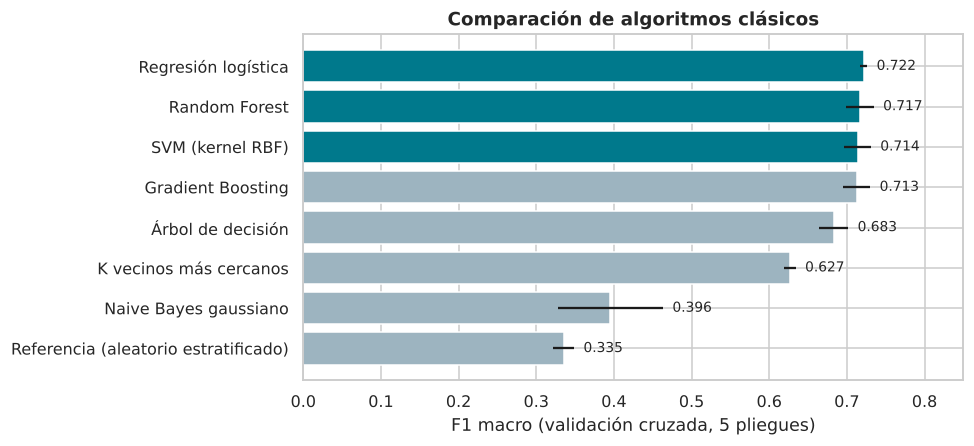

In [20]:
fig, ax = plt.subplots(figsize=(9, 4.2))
c = comparacion.sort_values("F1 macro")
ax.barh(c.index, c["F1 macro"], xerr=c["± F1"], color=["#00798C" if i >= len(c) - 3 else "#9DB4C0" for i in range(len(c))])
for i, (v, d) in enumerate(zip(c["F1 macro"], c["± F1"])):
    ax.text(v + d + 0.012, i, f"{v:.3f}", va="center", fontsize=9)
ax.set_xlim(0, 0.85); ax.set_xlabel("F1 macro (validación cruzada, 5 pliegues)")
ax.set_title("Comparación de algoritmos clásicos")
plt.tight_layout(); plt.savefig(FIGS / "06_comparacion.png", dpi=200, bbox_inches="tight"); plt.show()

Todos los modelos superan con holgura a la referencia aleatoria (F1 macro 0,335). Cuatro algoritmos quedan prácticamente empatados entre 0,713 y 0,722: regresión logística, Random Forest, SVM y Gradient Boosting.

La brecha entre entrenamiento y validación cuenta otra historia. Random Forest y Gradient Boosting casi memorizan el entrenamiento (0,969 y 1,000) y pierden más de 0,25 al validar, una señal clara de sobreajuste. La regresión logística apenas cae 0,033. Naive Bayes falla porque supone independencia y normalidad en variables muy correlacionadas y en su mayoría binarias tras el one-hot, y KNN se resiente con 107 dimensiones.

### 3.3 Ajuste de hiperparámetros
Se afinan los tres mejores con `GridSearchCV` sobre los mismos 5 pliegues, optimizando F1 macro.

In [21]:
rejillas = {
    "Regresión logística": (
        LogisticRegression(max_iter=5000, class_weight="balanced", random_state=SEED),
        {"modelo__C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10],
         "modelo__class_weight": [None, "balanced"]}),
    "Random Forest": (
        RandomForestClassifier(n_estimators=400, random_state=SEED, n_jobs=-1),
        {"modelo__max_depth": [None, 12, 20],
         "modelo__min_samples_leaf": [1, 3, 5],
         "modelo__max_features": ["sqrt", 0.3],
         "modelo__class_weight": ["balanced_subsample"]}),
    "SVM (kernel RBF)": (
        SVC(probability=True, class_weight="balanced", random_state=SEED),
        {"modelo__C": [0.3, 1, 3], "modelo__gamma": ["scale", 0.01, 0.003]}),
}
busquedas = {}
for nombre, (modelo, rejilla) in rejillas.items():
    gs = GridSearchCV(crear_pipeline(modelo), rejilla, cv=cv, scoring="f1_macro", n_jobs=-1)
    gs.fit(X_train, y_train)
    busquedas[nombre] = gs
    i = gs.best_index_
    print(f"{nombre:<20} F1 macro CV = {gs.best_score_:.4f} ± {gs.cv_results_['std_test_score'][i]:.4f}"
          f" | {({k.replace('modelo__', ''): v for k, v in gs.best_params_.items()})}")

Regresión logística  F1 macro CV = 0.7227 ± 0.0090 | {'C': 0.1, 'class_weight': 'balanced'}


Random Forest        F1 macro CV = 0.7258 ± 0.0156 | {'class_weight': 'balanced_subsample', 'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 3}


SVM (kernel RBF)     F1 macro CV = 0.7166 ± 0.0118 | {'C': 3, 'gamma': 0.01}


Tras el ajuste, Random Forest (0,726) y regresión logística (0,723) quedan a 0,003 de distancia, menos que la variación entre pliegues de cualquiera de los dos (0,009 y 0,016). Es un empate técnico.

In [22]:
nombre_final = max(busquedas, key=lambda k: busquedas[k].best_score_)
# Si la diferencia con la regresión logística es menor a 0,005 se prefiere la logística por interpretabilidad
if busquedas[nombre_final].best_score_ - busquedas["Regresión logística"].best_score_ < 0.005:
    nombre_final = "Regresión logística"
modelo_final = busquedas[nombre_final].best_estimator_
print("Modelo seleccionado:", nombre_final)
print("Hiperparámetros:", {k.replace("modelo__", ""): v for k, v in busquedas[nombre_final].best_params_.items()})

Modelo seleccionado: Regresión logística
Hiperparámetros: {'C': 0.1, 'class_weight': 'balanced'}


**¿Por qué regresión logística?** Con un empate así se prefiere el modelo más simple, y aquí la logística gana en todo lo demás:

1. **Estabilidad:** la menor variación entre pliegues (± 0,009) y la menor brecha con el entrenamiento.
2. **Interpretabilidad:** cada coeficiente dice en qué dirección empuja una variable. El usuario final es un consejero o un coordinador académico que necesita entender por qué se marca a un estudiante.
3. **Probabilidades útiles:** la app no solo da la clase, también la probabilidad de deserción para clasificar el riesgo en bajo, medio y alto.
4. **Liviano:** el pipeline completo pesa unos KB y predice al instante en Streamlit.

La configuración final es multinomial con regularización L2, *C* = 0,1 (regularización fuerte, coherente con las variables redundantes) y pesos de clase balanceados.

### 3.4 Curva de aprendizaje del modelo seleccionado

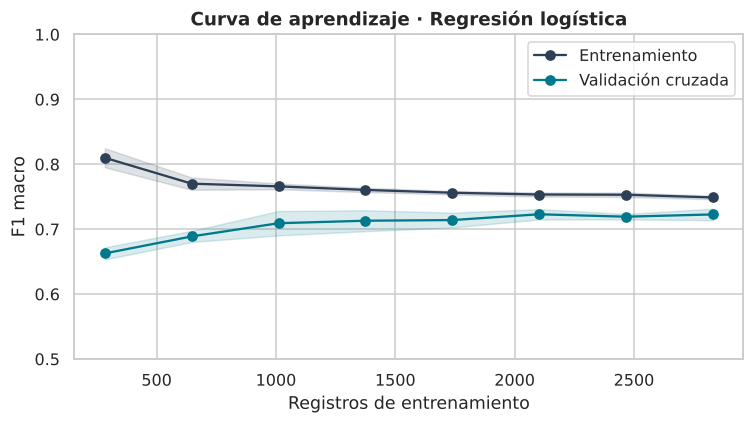

Brecha final train - validación: 0.026


In [23]:
tam, tr, va = learning_curve(modelo_final, X_train, y_train, cv=cv, scoring="f1_macro",
                             train_sizes=np.linspace(0.1, 1.0, 8), n_jobs=-1, random_state=SEED)
fig, ax = plt.subplots(figsize=(7, 4))
for s, lab, col in [(tr, "Entrenamiento", "#2E4057"), (va, "Validación cruzada", "#00798C")]:
    ax.plot(tam, s.mean(1), "o-", label=lab, color=col)
    ax.fill_between(tam, s.mean(1) - s.std(1), s.mean(1) + s.std(1), alpha=.15, color=col)
ax.set_xlabel("Registros de entrenamiento"); ax.set_ylabel("F1 macro"); ax.set_ylim(0.5, 1)
ax.set_title(f"Curva de aprendizaje · {nombre_final}"); ax.legend()
plt.tight_layout(); plt.savefig(FIGS / "07_curva_aprendizaje.png", dpi=200, bbox_inches="tight"); plt.show()
print(f"Brecha final train - validación: {tr.mean(1)[-1] - va.mean(1)[-1]:.3f}")

Las dos curvas convergen y la brecha final es de solo 0,026: el modelo generaliza, no memoriza. La validación todavía sube un poco al final, así que más datos ayudarían, aunque con rendimientos decrecientes.

---
## Paso 4 · Evaluación en el conjunto de prueba

El conjunto de prueba (885 estudiantes) no se usó en ninguna decisión anterior, así que estas cifras estiman cómo se comportaría el modelo con estudiantes nuevos.

In [24]:
y_pred = modelo_final.predict(X_test)
y_proba = modelo_final.predict_proba(X_test)
clases = list(modelo_final.classes_)

def resumen_metricas(y_true, y_hat, proba):
    return {
        "Exactitud": accuracy_score(y_true, y_hat),
        "Exactitud balanceada": balanced_accuracy_score(y_true, y_hat),
        "F1 macro": f1_score(y_true, y_hat, average="macro"),
        "F1 ponderado": f1_score(y_true, y_hat, average="weighted"),
        "Precisión macro": precision_score(y_true, y_hat, average="macro"),
        "Sensibilidad macro": recall_score(y_true, y_hat, average="macro"),
        "ROC-AUC (OvR macro)": roc_auc_score(y_true, proba, multi_class="ovr", average="macro"),
        "Kappa de Cohen": cohen_kappa_score(y_true, y_hat),
        "MCC": matthews_corrcoef(y_true, y_hat),
    }

met_test = resumen_metricas(y_test, y_pred, y_proba)

# Intervalos de confianza al 95 % por bootstrap (1.000 remuestreos del conjunto de prueba)
rng = np.random.default_rng(SEED)
yt, yp = y_test.to_numpy(), np.asarray(y_pred)
boot = {"Exactitud": [], "F1 macro": [], "ROC-AUC (OvR macro)": []}
for _ in range(1000):
    i = rng.integers(0, len(yt), len(yt))
    boot["Exactitud"].append(accuracy_score(yt[i], yp[i]))
    boot["F1 macro"].append(f1_score(yt[i], yp[i], average="macro"))
    boot["ROC-AUC (OvR macro)"].append(roc_auc_score(yt[i], y_proba[i], multi_class="ovr", average="macro"))
ic = {k: np.percentile(v, [2.5, 97.5]) for k, v in boot.items()}

tabla_test = pd.DataFrame({"valor": met_test})
tabla_test["IC 95 %"] = [f"[{ic[k][0]:.3f} – {ic[k][1]:.3f}]" if k in ic else "" for k in tabla_test.index]
tabla_test

,valor,IC 95 %
Exactitud,0.740,[0.714 – 0.768]
Exactitud balanceada,0.696,
F1 macro,0.691,[0.659 – 0.722]
F1 ponderado,0.749,
Precisión macro,0.697,
Sensibilidad macro,0.696,
ROC-AUC (OvR macro),0.874,[0.853 – 0.893]
Kappa de Cohen,0.585,
MCC,0.588,


In [25]:
print(classification_report(y_test, y_pred, labels=pp.ORDEN_CLASES, digits=3))

              precision    recall  f1-score   support

   Deserción      0.822     0.701     0.757       284
 Matriculado      0.415     0.553     0.474       159
    Graduado      0.854     0.833     0.843       442

    accuracy                          0.740       885
   macro avg      0.697     0.696     0.691       885
weighted avg      0.765     0.740     0.749       885



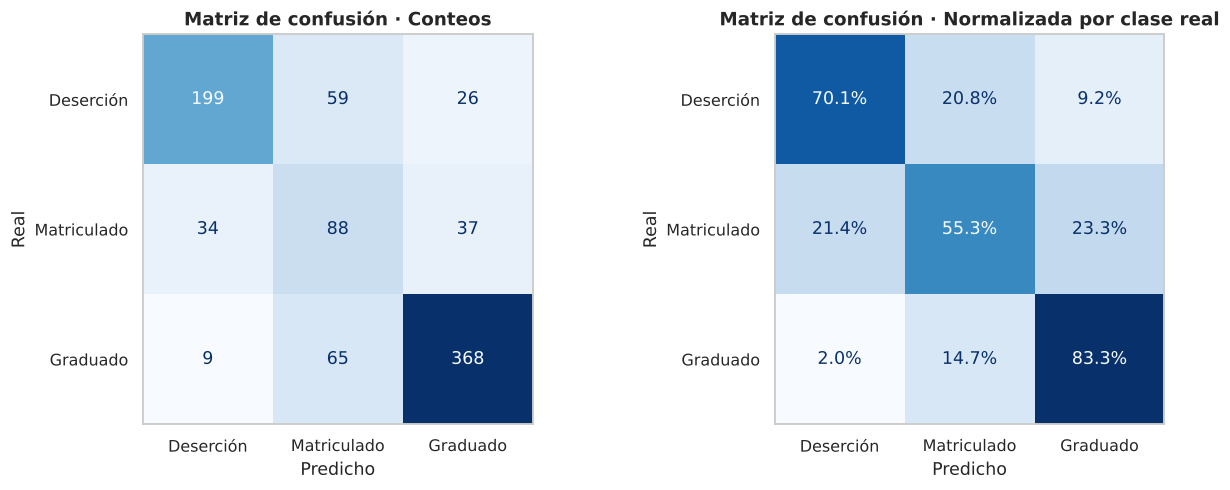

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for ax, norm, t in [(axes[0], None, "Conteos"), (axes[1], "true", "Normalizada por clase real")]:
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, labels=pp.ORDEN_CLASES, normalize=norm,
                                            cmap="Blues", values_format=".0f" if norm is None else ".1%",
                                            ax=ax, colorbar=False)
    ax.set_title(f"Matriz de confusión · {t}"); ax.set_xlabel("Predicho"); ax.set_ylabel("Real"); ax.grid(False)
plt.tight_layout(); plt.savefig(FIGS / "08_confusion.png", dpi=200, bbox_inches="tight"); plt.show()

El modelo detecta al **70,1 % de los estudiantes que de verdad desertaron** (199 de 284), y cuando predice deserción acierta el 82,2 % de las veces. *Graduado* es la clase mejor resuelta (F1 0,843). El punto débil es *Matriculado* (F1 0,474): es una clase intermedia por naturaleza, estudiantes atrasados que todavía no se van, y se confunde hacia los dos lados.

Para una alerta temprana lo que importa es que los errores graves son pocos: solo 9 graduados (2,0 %) se confunden con desertores y 26 desertores (9,2 %) pasan como graduados. El resto de los errores cae en la clase intermedia, que de todas formas merece seguimiento.

En prueba el F1 macro (0,691; IC 95 % de 0,659 a 0,722) queda algo por debajo del promedio de validación cruzada (0,723), aunque dentro del intervalo: es la variación esperable en una muestra de 885 estudiantes. El ROC-AUC de 0,874 indica que el modelo ordena bien a los estudiantes según su riesgo, y el kappa de 0,585 refleja un acuerdo moderado, bastante por encima del azar.

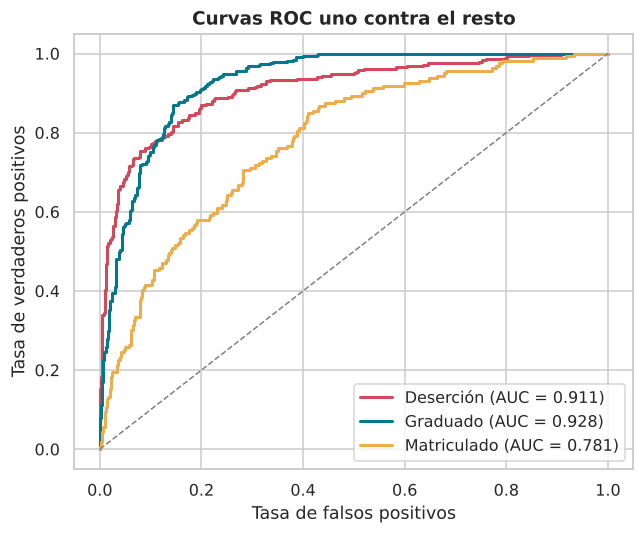

In [27]:
y_bin = label_binarize(y_test, classes=clases)
fig, ax = plt.subplots(figsize=(6, 5))
for k, c in enumerate(clases):
    fpr, tpr, _ = roc_curve(y_bin[:, k], y_proba[:, k])
    ax.plot(fpr, tpr, color=COLORES[c], lw=2, label=f"{c} (AUC = {auc(fpr, tpr):.3f})")
ax.plot([0, 1], [0, 1], "--", color="gray", lw=1)
ax.set_xlabel("Tasa de falsos positivos"); ax.set_ylabel("Tasa de verdaderos positivos")
ax.set_title("Curvas ROC uno contra el resto"); ax.legend(loc="lower right")
plt.tight_layout(); plt.savefig(FIGS / "09_roc.png", dpi=200, bbox_inches="tight"); plt.show()

### 4.1 ¿Qué variables pesan más?
Se usa **importancia por permutación** sobre el conjunto de prueba: se desordena una variable original a la vez y se mide cuánto cae el F1 macro. Tiene la ventaja de trabajar sobre las variables tal como las entiende un usuario (no sobre las columnas one-hot) y de ser válida para cualquier modelo.

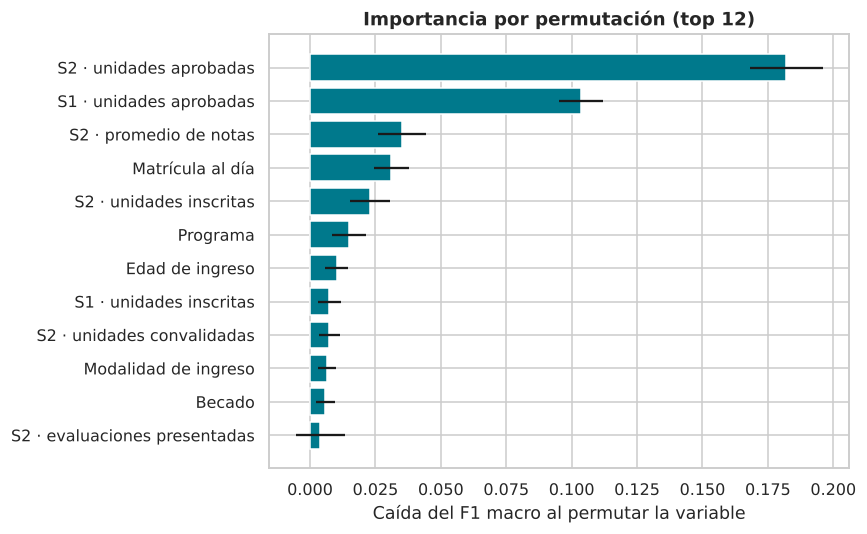

,variable,nombre,caida_f1,desv
0,s2_aprobadas,S2 · unidades aprobadas,0.182,0.014
1,s1_aprobadas,S1 · unidades aprobadas,0.103,0.009
2,s2_nota,S2 · promedio de notas,0.035,0.009
3,matricula_al_dia,Matrícula al día,0.031,0.007
4,s2_inscritas,S2 · unidades inscritas,0.023,0.008
5,programa,Programa,0.015,0.006
6,edad_ingreso,Edad de ingreso,0.010,0.004
7,s1_inscritas,S1 · unidades inscritas,0.007,0.004
8,s2_convalidadas,S2 · unidades convalidadas,0.007,0.004
9,modo_ingreso,Modalidad de ingreso,0.006,0.003


In [28]:
perm = permutation_importance(modelo_final, X_test, y_test, scoring="f1_macro", n_repeats=15,
                              random_state=SEED, n_jobs=-1)
importancia = (pd.DataFrame({"variable": X_test.columns, "caida_f1": perm.importances_mean,
                             "desv": perm.importances_std})
               .sort_values("caida_f1", ascending=False).reset_index(drop=True))
importancia.insert(1, "nombre", importancia["variable"].map(pp.ETIQUETAS))
top = importancia.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top["nombre"], top["caida_f1"], xerr=top["desv"], color="#00798C")
ax.set_xlabel("Caída del F1 macro al permutar la variable"); ax.set_title("Importancia por permutación (top 12)")
plt.tight_layout(); plt.savefig(FIGS / "10_importancia.png", dpi=200, bbox_inches="tight"); plt.show()
importancia.head(12).round(4)

Las unidades aprobadas dominan: si se desordenan las del segundo semestre el F1 macro cae 0,182, y con las del primero, 0,103. Después vienen el promedio del segundo semestre y tener la matrícula al día, lo que confirma lo visto en el EDA: la deserción tiene un componente académico y otro económico. Programa, edad, modalidad de ingreso y beca pesan menos, pero suman.

### 4.2 ¿Qué tan temprano se puede alertar?
El modelo principal usa información de todo el primer año. Para una alerta temprana real interesa saber cuánto se pierde si solo se tiene la información de matrícula o la del primer semestre. Se entrena el mismo tipo de modelo con los tres conjuntos de variables y se evalúa en el mismo conjunto de prueba.

In [29]:
params_final = {k.replace("modelo__", ""): v for k, v in busquedas[nombre_final].best_params_.items()}
modelos_escenario, filas_esc = {}, []
for esc, desc in pp.ESCENARIOS.items():
    base = clone(modelo_final.named_steps["modelo"])
    pipe = crear_pipeline(base, esc)
    cols_esc = pp.columnas(esc)["entradas"]
    pipe.fit(X_train[cols_esc], y_train)
    pr, pb = pipe.predict(X_test[cols_esc]), pipe.predict_proba(X_test[cols_esc])
    modelos_escenario[esc] = pipe
    filas_esc.append({"escenario": desc, "variables de entrada": len(cols_esc),
                      "Exactitud": accuracy_score(y_test, pr), "F1 macro": f1_score(y_test, pr, average="macro"),
                      "Sensibilidad Deserción": recall_score(y_test, pr, labels=["Deserción"], average="macro"),
                      "ROC-AUC": roc_auc_score(y_test, pb, multi_class="ovr")})
escenarios = pd.DataFrame(filas_esc).set_index("escenario")
escenarios.round(3)

,variables de entrada,Exactitud,F1 macro,Sensibilidad Deserción,ROC-AUC
escenario,,,,,
Al ingreso (sin notas),23,0.591,0.560,0.556,0.767
Tras el 1.er semestre,30,0.707,0.655,0.658,0.861
Tras el 1.er año (modelo principal),36,0.740,0.691,0.701,0.874


Con solo los datos de matrícula el modelo llega a un F1 macro de 0,560 y detecta al 55,6 % de los desertores. No alcanza para decisiones individuales, pero sí para priorizar acompañamiento desde el primer día. Al sumar el primer semestre, el F1 sube a 0,655, la detección de deserción a 65,8 % y el ROC-AUC a 0,861, muy cerca del modelo completo (0,874).

En la práctica, el cierre del primer semestre ofrece el mejor equilibrio entre anticipación y acierto: se pierde poco frente al modelo anual y se gana un semestre entero para intervenir. Por eso la app permite elegir el escenario según la información disponible.

---
## Paso 5 · Exportación de artefactos para Streamlit
Se guardan los tres pipelines entrenados (cada uno incluye limpieza de faltantes, ingeniería de características, codificación y modelo) junto con un archivo de metadatos con las métricas, para que la app las muestre sin recalcularlas.

> Los pipelines se guardan entrenados con el 80 % de los datos para que las métricas que muestra la app correspondan exactamente a lo evaluado en este notebook.

In [30]:
for esc, pipe in modelos_escenario.items():
    joblib.dump(pipe, f"modelo/modelo_{esc}.joblib", compress=3)

cm = confusion_matrix(y_test, y_pred, labels=pp.ORDEN_CLASES)
reporte = classification_report(y_test, y_pred, labels=pp.ORDEN_CLASES, output_dict=True)
metadatos = {
    "modelo": nombre_final,
    "hiperparametros": {k: (v if isinstance(v, (int, float, str)) or v is None else str(v)) for k, v in params_final.items()},
    "version_sklearn": sklearn.__version__,
    "semilla": SEED,
    "n_train": int(len(X_train)), "n_test": int(len(X_test)),
    "metricas_test": {k: round(float(v), 4) for k, v in met_test.items()},
    "ic95": {k: [round(float(a), 4) for a in v] for k, v in ic.items()},
    "por_clase": {c: {m: round(float(reporte[c][m]), 4) for m in ("precision", "recall", "f1-score", "support")}
                  for c in pp.ORDEN_CLASES},
    "matriz_confusion": {"clases": pp.ORDEN_CLASES, "valores": cm.tolist()},
    "comparacion_cv": comparacion[["F1 macro", "± F1", "Exactitud", "Exactitud balanceada", "ROC-AUC"]]
                      .round(4).reset_index().to_dict(orient="records"),
    "importancia": importancia.head(15).round(4).to_dict(orient="records"),
    "escenarios": escenarios.round(4).reset_index().to_dict(orient="records"),
}
Path("modelo/metadatos.json").write_text(json.dumps(metadatos, ensure_ascii=False, indent=2), encoding="utf-8")

# Archivo de ejemplo para la predicción por lotes en la app (estudiantes del conjunto de prueba)
ejemplo = X_test.sample(25, random_state=SEED).copy()
ejemplo.insert(0, "id_estudiante", [f"EST-{i:04d}" for i in ejemplo.index])
ejemplo.to_csv("data/estudiantes_ejemplo.csv", index=False)

for f in sorted(Path("modelo").iterdir()):
    print(f"{f.name:<28} {f.stat().st_size / 1024:>8.1f} KB")

metadatos.json                    5.5 KB
modelo_anual.joblib               6.4 KB
modelo_ingreso.joblib             5.3 KB
modelo_semestre1.joblib           5.8 KB


In [31]:
# Prueba de humo: recargar el modelo desde disco y predecir un estudiante, tal como lo hará la app
m = joblib.load("modelo/modelo_anual.joblib")
uno = X_test.iloc[[0]]
print("Real:", y_test.iloc[0], "| Predicho:", m.predict(uno)[0])
print(dict(zip(m.classes_, m.predict_proba(uno)[0].round(3))))

Real: Graduado | Predicho: Graduado
{'Deserción': np.float64(0.019), 'Graduado': np.float64(0.902), 'Matriculado': np.float64(0.079)}


---
## 6. Conclusiones

- **Respuesta a la pregunta orientadora.** Con datos que cualquier institución ya tiene (ingreso, situación de pago y notas del primer año), una regresión logística clasifica a estudiantes que nunca vio con 74,0 % de exactitud, F1 macro de 0,691 y ROC-AUC de 0,874. Detecta al 70 % de quienes desertan y acierta el 82 % de las veces que da esa alerta. La app de Streamlit pone ese conocimiento en manos de usuarios no técnicos.
- **Sin nulos no significa limpio.** El dataset no tenía faltantes ni duplicados, pero escondía 180 registros con ceros que en realidad eran ausencia de información (75 de ellos, graduados con cero materias inscritas). Tratarlos como faltantes evitó que el modelo aprendiera una relación falsa.
- **Las señales más fuertes son académicas y económicas.** Las unidades aprobadas en el primer año y tener la matrícula al día pesan más que el puntaje de admisión. Para la gestión institucional esto apunta a dos frentes concretos: tutorías tempranas y apoyos financieros oportunos.
- **El modelo más simple fue el más confiable.** Los ensambles empataron en validación, pero sobreajustaban. La regresión logística ofreció el mismo rendimiento con más estabilidad y la posibilidad de explicar cada predicción.
- **Limitaciones.** Los datos vienen de una sola institución portuguesa, la clase *Matriculado* sigue siendo difícil de separar y el modelo usa variables sensibles como género y edad. Antes de aplicarlo en Colombia habría que reentrenarlo con datos locales (por ejemplo, del SPADIES) y revisar posibles sesgos. Su papel es apoyar el criterio del consejero académico, no reemplazarlo.

## Referencias

Laboratorio de Economía de la Educación. (2023). *Deserción en la educación superior en Colombia* (Informe de análisis estadístico n.º 74). Pontificia Universidad Javeriana. https://www.javeriana.edu.co/recursosdb/5581483/8102914/INFORME-74-DESERCIO%CC%81N-EDU-SUPERIOR2023.pdf

Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., Blondel, M., Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A., Cournapeau, D., Brucher, M., Perrot, M., & Duchesnay, É. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830.

Realinho, V., Machado, J., Baptista, L., & Martins, M. V. (2022). Predicting student dropout and academic success. *Data, 7*(11), Artículo 146. https://doi.org/10.3390/data7110146

Realinho, V., Vieira Martins, M., Machado, J., & Baptista, L. (2021). *Predict students' dropout and academic success* [Conjunto de datos]. UCI Machine Learning Repository. https://doi.org/10.24432/C5MC89